In [1]:
import scanpy as sc 
import anndata as ann
import numpy as np
import scipy as sp
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib import colors
import seaborn as sns
from matplotlib.ticker import LogLocator, LogFormatterMathtext
import scanpy as sc
from matplotlib.colors import Normalize
import louvain
import matplotlib.lines as mlines



## Loading and preprocessing

In [2]:
adata = sc.read_h5ad('INPUT/scRNAseq/scRNAseq_raw.h5ad')
adata.obs['Time_int'] = adata.obs['Time'].str.replace('h', '').astype(int)  
adata

AnnData object with n_obs × n_vars = 36233 × 32285
    obs: 'dataset', 'Sample', 'Time', 'Condition', 'Time_int'

## Quality control

In [3]:
# Quality control - calculate QC covariates
adata.obs['n_counts'] = adata.X.sum(1)
adata.obs['log_counts'] = np.log(adata.obs['n_counts'])
adata.obs['n_genes'] = (adata.X > 0).sum(1)

mt_gene_mask = np.flatnonzero([gene.startswith('mt-') for gene in adata.var_names])
# the `.A1` is only necessary as X is sparse (to transform to a dense array after summing)
adata.obs['mt_frac'] = np.sum(adata[:, mt_gene_mask].X, axis=1).A1/adata.obs['n_counts']

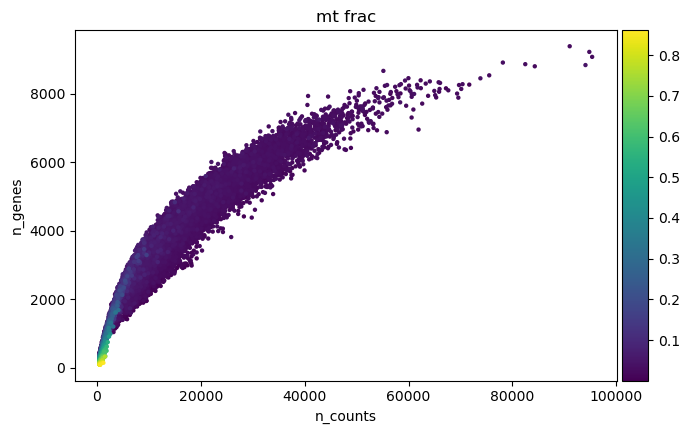

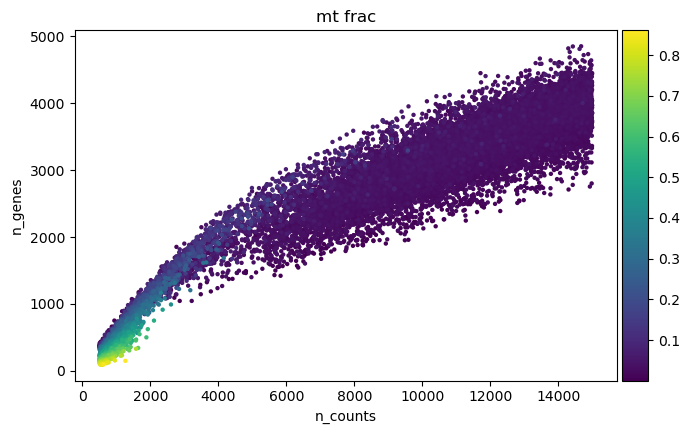

In [4]:
#Data quality summary plots
p1 = sc.pl.scatter(adata, 'n_counts', 'n_genes', color='mt_frac', size=40)
p2 = sc.pl.scatter(adata[adata.obs['n_counts']<15000], 'n_counts', 'n_genes', 
                   color='mt_frac', size=40)

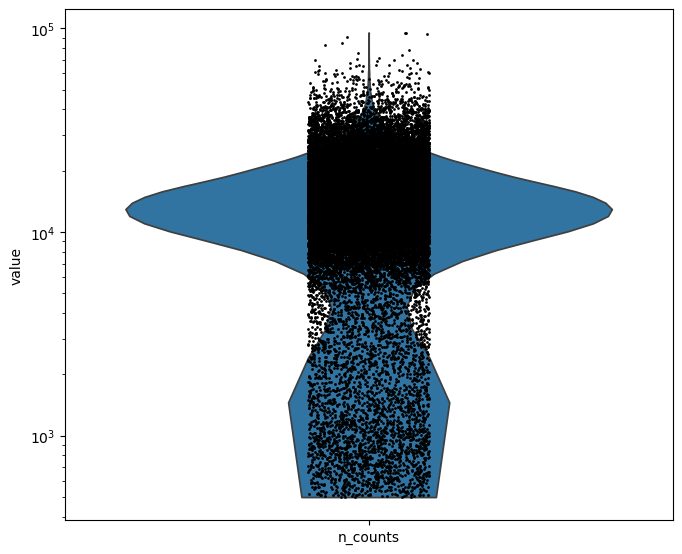

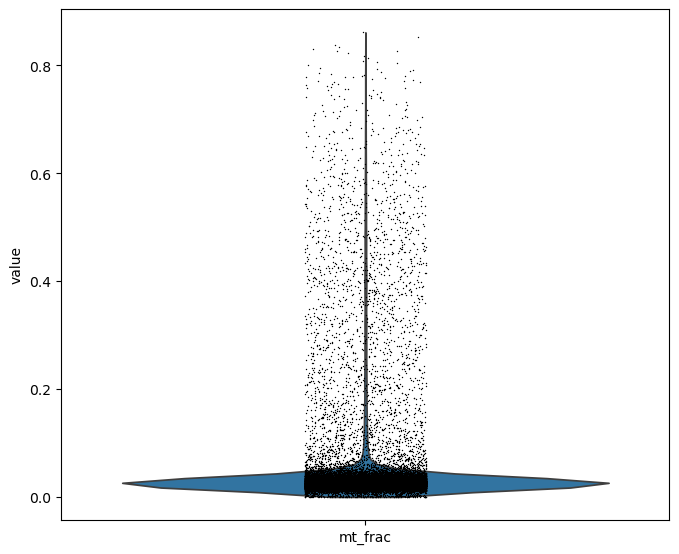

In [5]:
#Sample quality plots
rcParams['figure.figsize']=(7,7)
t1 = sc.pl.violin(adata, 'n_counts',
                  #groupby='sample',
                  size=2, log=True, cut=0)
t2 = sc.pl.violin(adata, 'mt_frac')

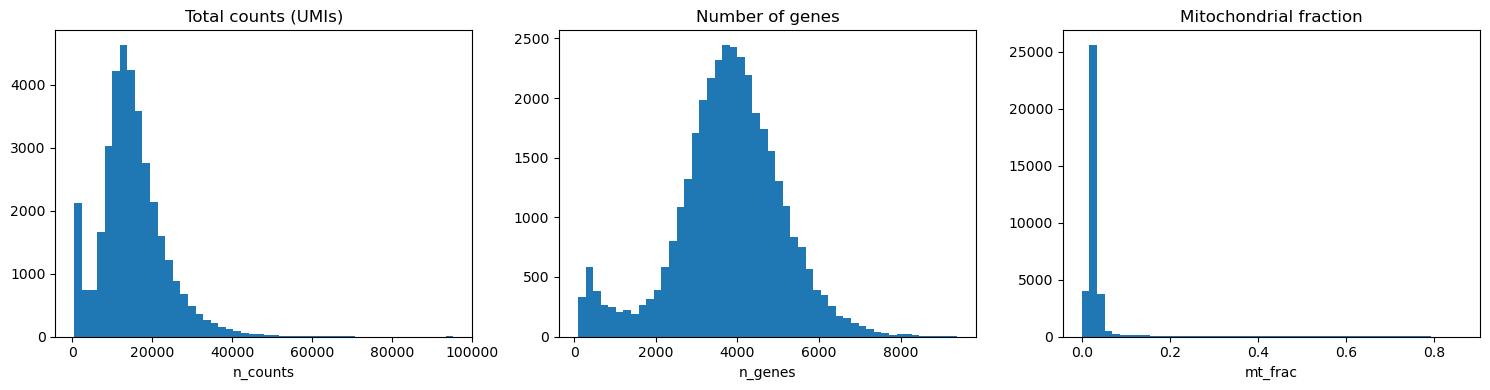

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# total counts
axes[0].hist(adata.obs["n_counts"], bins=50)
axes[0].set_title("Total counts (UMIs)")
axes[0].set_xlabel("n_counts")

# number of genes
axes[1].hist(adata.obs["n_genes"], bins=50)
axes[1].set_title("Number of genes")
axes[1].set_xlabel("n_genes")

# mitochondrial fraction
axes[2].hist(adata.obs["mt_frac"], bins=50)
axes[2].set_title("Mitochondrial fraction")
axes[2].set_xlabel("mt_frac")

plt.tight_layout()
plt.show()


## Filtering

In [7]:
# Filter cells according to identified QC thresholds:
print('Total number of cells: {:d}'.format(adata.n_obs))

sc.pp.filter_cells(adata, min_counts = 1000)
print('Number of cells after min count filter: {:d}'.format(adata.n_obs))

sc.pp.filter_cells(adata, max_counts = 40000)
print('Number of cells after max count filter: {:d}'.format(adata.n_obs))

adata = adata[adata.obs['mt_frac'] < 0.15]
print('Number of cells after MT filter: {:d}'.format(adata.n_obs))

sc.pp.filter_cells(adata, min_genes = 700)
print('Number of cells after gene filter: {:d}'.format(adata.n_obs))

Total number of cells: 36233
Number of cells after min count filter: 35198
Number of cells after max count filter: 34794
Number of cells after MT filter: 33961


/Users/mleonard/opt/anaconda3/envs/corrections/lib/python3.10/site-packages/scanpy/preprocessing/_simple.py:168: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs["n_genes"] = number


Number of cells after gene filter: 33927


In [8]:
#Filter genes:
print('Total number of genes: {:d}'.format(adata.n_vars))

# Min 20 cells - filters out 0 count genes
sc.pp.filter_genes(adata, min_cells=20)
print('Number of genes after cell filter: {:d}'.format(adata.n_vars))

Total number of genes: 32285
Number of genes after cell filter: 21777


## Processing

In [9]:
sc.pp.normalize_total(adata)
sc.pp.log1p(adata)


## Dimensionality reduction

In [10]:
sc.pp.highly_variable_genes(adata, n_top_genes=2000)



OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


In [11]:
sc.pp.highly_variable_genes(adata, flavor='cell_ranger', n_top_genes=2000)
sc.pp.pca(adata, n_comps=50, use_highly_variable=True, svd_solver='arpack',random_state=0)
sc.pp.neighbors(adata,  random_state=0)
sc.tl.umap(adata,  random_state=0)


/Users/mleonard/opt/anaconda3/envs/corrections/lib/python3.10/site-packages/scanpy/preprocessing/_pca.py:374: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  warn(msg, FutureWarning)
2026-01-06 16:29:26.490002: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


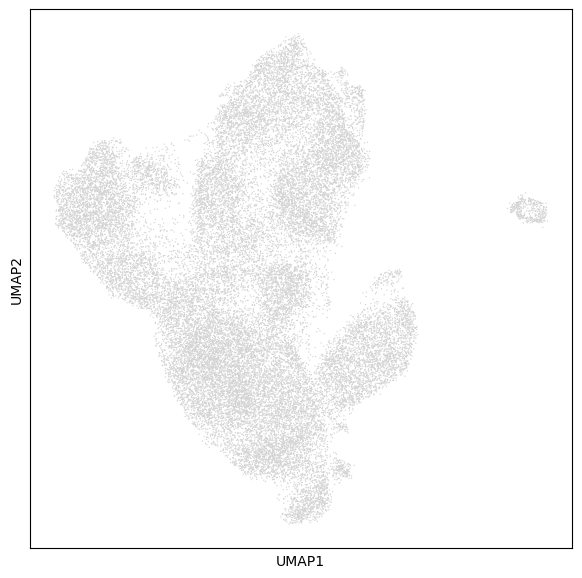

In [12]:
sc.pl.umap(adata)

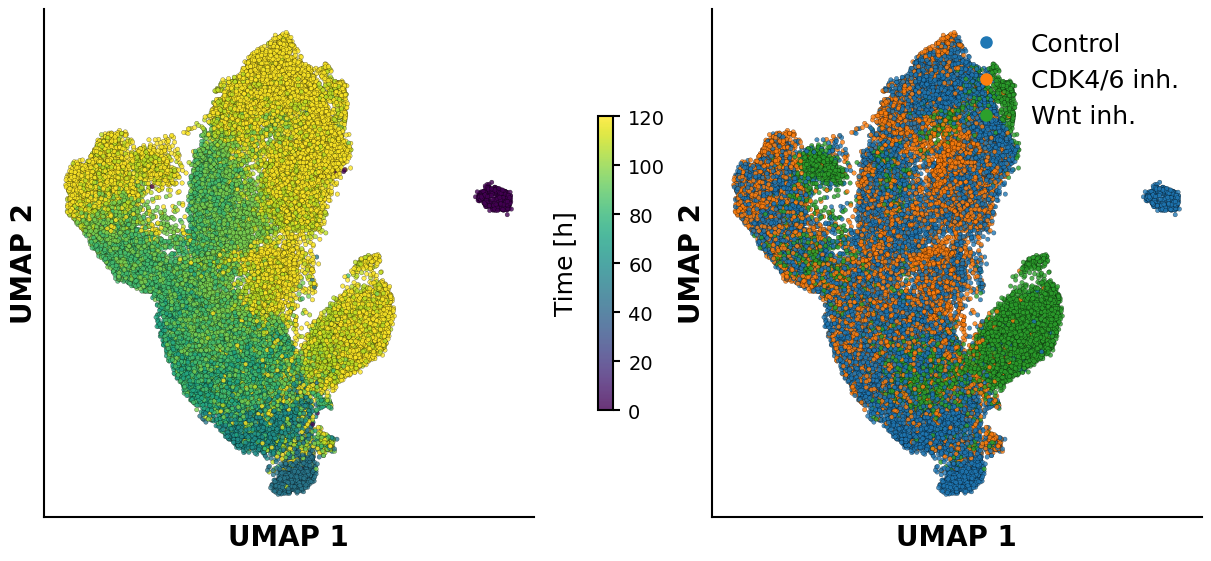

In [ ]:


# Extract 'Condition' and 'Time_int' columns
condition_column = adata.obs['Condition'].values
time_column = adata.obs['Time_int'].values


unique_conditions = pd.unique(condition_column)
palette = sns.color_palette("tab10", len(unique_conditions))  # Adjust palette if desired
condition_colors = dict(zip(unique_conditions, palette))
condition_colors_mapped = np.array([condition_colors[cond] for cond in condition_column])

# Random permutation to mix point order 
rng = np.random.default_rng(42)  
coords = adata.obsm['X_umap']
idx = rng.permutation(coords.shape[0])

# Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5), constrained_layout=True)

# ===== Left plot: Time_int (continuous) =====
ax1 = axes[0]
scatter_time = ax1.scatter(
    coords[idx, 0],
    coords[idx, 1],
    c=time_column[idx],          # Continuous color
    cmap="viridis",
    s=10, alpha=0.8,
    edgecolor="k", linewidth=0.2
)

# Aesthetic settings
for side in ["top", "right"]:
    ax1.spines[side].set_visible(False)
for side in ["bottom", "left"]:
    ax1.spines[side].set_linewidth(1.5)
ax1.set_xticks([])
ax1.set_yticks([])
ax1.set_xlabel("UMAP 1", fontsize=20, fontweight="bold")
ax1.set_ylabel("UMAP 2", fontsize=20, fontweight="bold")

# === Add colorbar for Time_int ===
cbar = plt.colorbar(scatter_time, ax=ax1, fraction=0.03, pad=0.04)
cbar.ax.yaxis.set_label_position("left")   
cbar.set_label(r"Time [h]", fontsize=18, labelpad=15, rotation=90)  
cbar.ax.tick_params(labelsize=14, width=1.5, length=5, pad=6)       
cbar.outline.set_linewidth(1.5)

# ===== Right plot: Condition (categorical) =====
ax2 = axes[1]
scatter_condition = ax2.scatter(
    coords[idx, 0],
    coords[idx, 1],
    c=condition_colors_mapped[idx],
    s=10, alpha=0.8,
    edgecolor="k", linewidth=0.2
)

# Aesthetic settings
for side in ["top", "right"]:
    ax2.spines[side].set_visible(False)
for side in ["bottom", "left"]:
    ax2.spines[side].set_linewidth(1.5)
ax2.set_xticks([])
ax2.set_yticks([])
ax2.set_xlabel("UMAP 1", fontsize=20, fontweight="bold")
ax2.set_ylabel("UMAP 2", fontsize=20, fontweight="bold")

# ===== Legend for conditions =====
condition_labels = {
    "ctrl": "Control",
    "cdk": "CDK4/6 inh.",
    "porcn": "Wnt inh."
}

handles = [
    plt.Line2D(
        [0], [0], marker='o', color=color,
        label=condition_labels.get(cond, cond),
        markersize=8, linestyle=''
    )
    for cond, color in condition_colors.items()
]

ax2.legend(
    handles=handles,
    title="",
    title_fontsize=18,
    fontsize=18,
    loc="upper right",
    frameon=False
)

# Save and show
plt.savefig(
    "figures/umap_time_condition.png",  
    format="png",
    dpi=500,                             
    bbox_inches="tight",
    transparent=True
)

plt.show()


## Densities

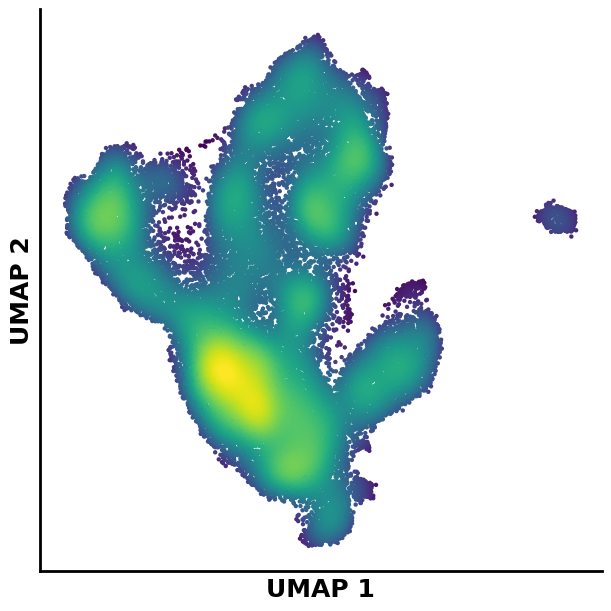

In [15]:
from scipy.stats import gaussian_kde

# --- Extract UMAP coordinates ---
X = adata.obsm["X_umap"][:, 0]
Y = adata.obsm["X_umap"][:, 1]

# --- KDE density ---
xy = np.vstack([X, Y])
kde = gaussian_kde(xy, bw_method=0.15)
density = kde(xy)

# Sort by density so dense regions are on top
idx = density.argsort()
X_d, Y_d, D_d = X[idx], Y[idx], density[idx]

# --- Plot ---
fig, ax = plt.subplots(figsize=(6, 6), constrained_layout=True)

ax.scatter(
    X_d, Y_d,
    c=D_d,
    s=10,
    cmap="viridis",
    edgecolor="none"
)

ax.set_xlabel("UMAP 1", fontsize=18, fontweight="bold")
ax.set_ylabel("UMAP 2", fontsize=18, fontweight="bold")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_linewidth(2)
ax.spines["left"].set_linewidth(2)

ax.set_xticks([])
ax.set_yticks([])

fig.savefig(
    "figures/umap_density_kde.png",
    dpi=500,
    bbox_inches="tight",
    transparent=True
)

plt.show()

## Cell type annotation

In [15]:
cell_type_markers = pd.read_csv('INPUT/marker_genes.csv')

cell_type_markers_dict = {
    col: cell_type_markers[col].dropna().tolist()
    for col in cell_type_markers.columns
    if not col.startswith("Unnamed")
}


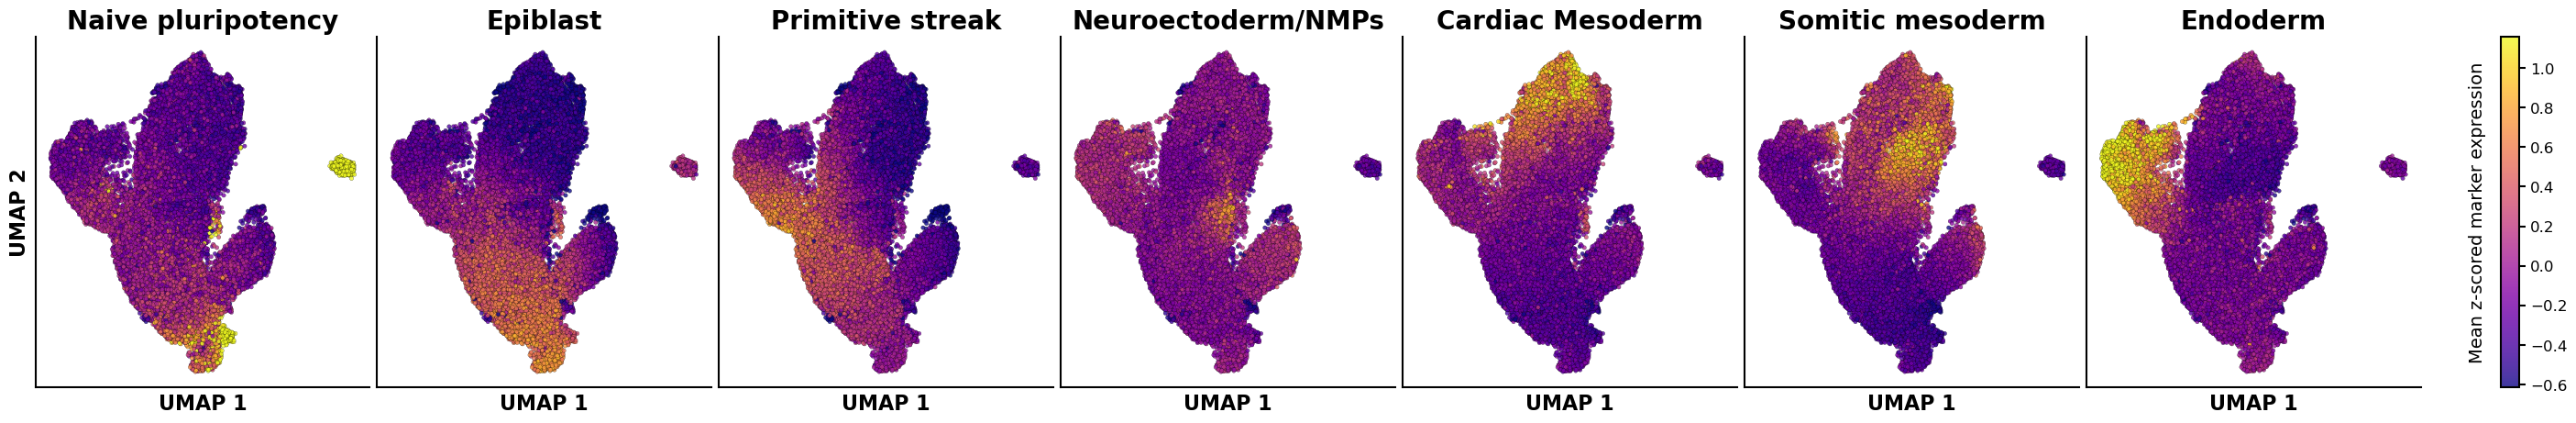

In [ ]:

def _to_dense(X):
    """Convert sparse-like matrices to dense numpy arrays."""
    return X.toarray() if hasattr(X, "toarray") else np.asarray(X)


# ----------------------------
# 1) Modify marker dictionary
#    - Rename Ectoderm -> Neuroectoderm/NMPs
# ----------------------------
markers = {k: list(v) for k, v in cell_type_markers_dict.items()}
if "Ectoderm" in markers:
    markers["Neuroectoderm/NMPs"] = markers.pop("Ectoderm")


# ----------------------------
# 2) Compute mean z-scored marker expression 
# ----------------------------
marker_score = {}
for cell_type, genes in markers.items():
    genes_present = [g for g in genes if g in adata.var_names]
    if not genes_present:
        marker_score[cell_type] = np.full(adata.n_obs, np.nan)
        continue

    X = _to_dense(adata[:, genes_present].X).astype(float)  # cells x genes

    mu = np.nanmean(X, axis=0, keepdims=True)
    sigma = np.nanstd(X, axis=0, keepdims=True)
    sigma[sigma == 0] = np.nan  # avoid division by zero

    Z = (X - mu) / sigma
    marker_score[cell_type] = np.nanmean(Z, axis=1)


# ----------------------------
# 3) Plot
# ----------------------------
layout = [
    "Naive pluripotency",
    "Epiblast",
    "Primitive streak",
    "Neuroectoderm/NMPs",
    "Cardiac Mesoderm",
    "Somitic mesoderm",
    "Endoderm",
]

coords = adata.obsm["X_umap"]
rng = np.random.default_rng(42)
plot_order = rng.permutation(coords.shape[0])


# Shared color limits across panels (robust)
vals = []
for cell_type in layout:
    if cell_type in marker_score:
        vals.append(marker_score[cell_type])

if vals:
    vals = np.concatenate([v[~np.isnan(v)] for v in vals if np.any(~np.isnan(v))])
else:
    vals = np.array([0.0])

vmin, vmax = np.nanpercentile(vals, 1), np.nanpercentile(vals, 99)


fig, axes = plt.subplots(
    1, 7,
    figsize=(28, 4.5),
    constrained_layout=True,
    sharex=True,
    sharey=True,
)
axes = np.atleast_1d(axes)

last_sc = None
for ax, cell_type in zip(axes, layout):
    scores = marker_score.get(cell_type, np.full(adata.n_obs, np.nan))

    last_sc = ax.scatter(
        coords[plot_order, 0],
        coords[plot_order, 1],
        c=scores[plot_order],
        cmap="plasma",
        s=10,
        alpha=0.8,
        edgecolor="k",
        linewidth=0.2,
        vmin=vmin,
        vmax=vmax,
    )

    # Aesthetics 
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(cell_type, fontsize=20, fontweight="bold")

    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("bottom", "left"):
        ax.spines[side].set_linewidth(1.5)

# Single set of axis labels (shared axes)
axes[0].set_ylabel("UMAP 2", fontsize=16, fontweight="bold")
for i in range(7):
    axes[i].set_xlabel("UMAP 1", fontsize=16, fontweight="bold")

# Shared colorbar
cbar = fig.colorbar(last_sc, ax=axes.ravel().tolist(), fraction=0.02, pad=0.02)
cbar.ax.yaxis.set_label_position("left")
cbar.set_label(
    "Mean z-scored marker expression",
    fontsize=14,
    labelpad=12,
    rotation=90,
)
cbar.ax.tick_params(labelsize=12, width=1.5, length=5, pad=4)
cbar.outline.set_linewidth(1.5)

plt.show()


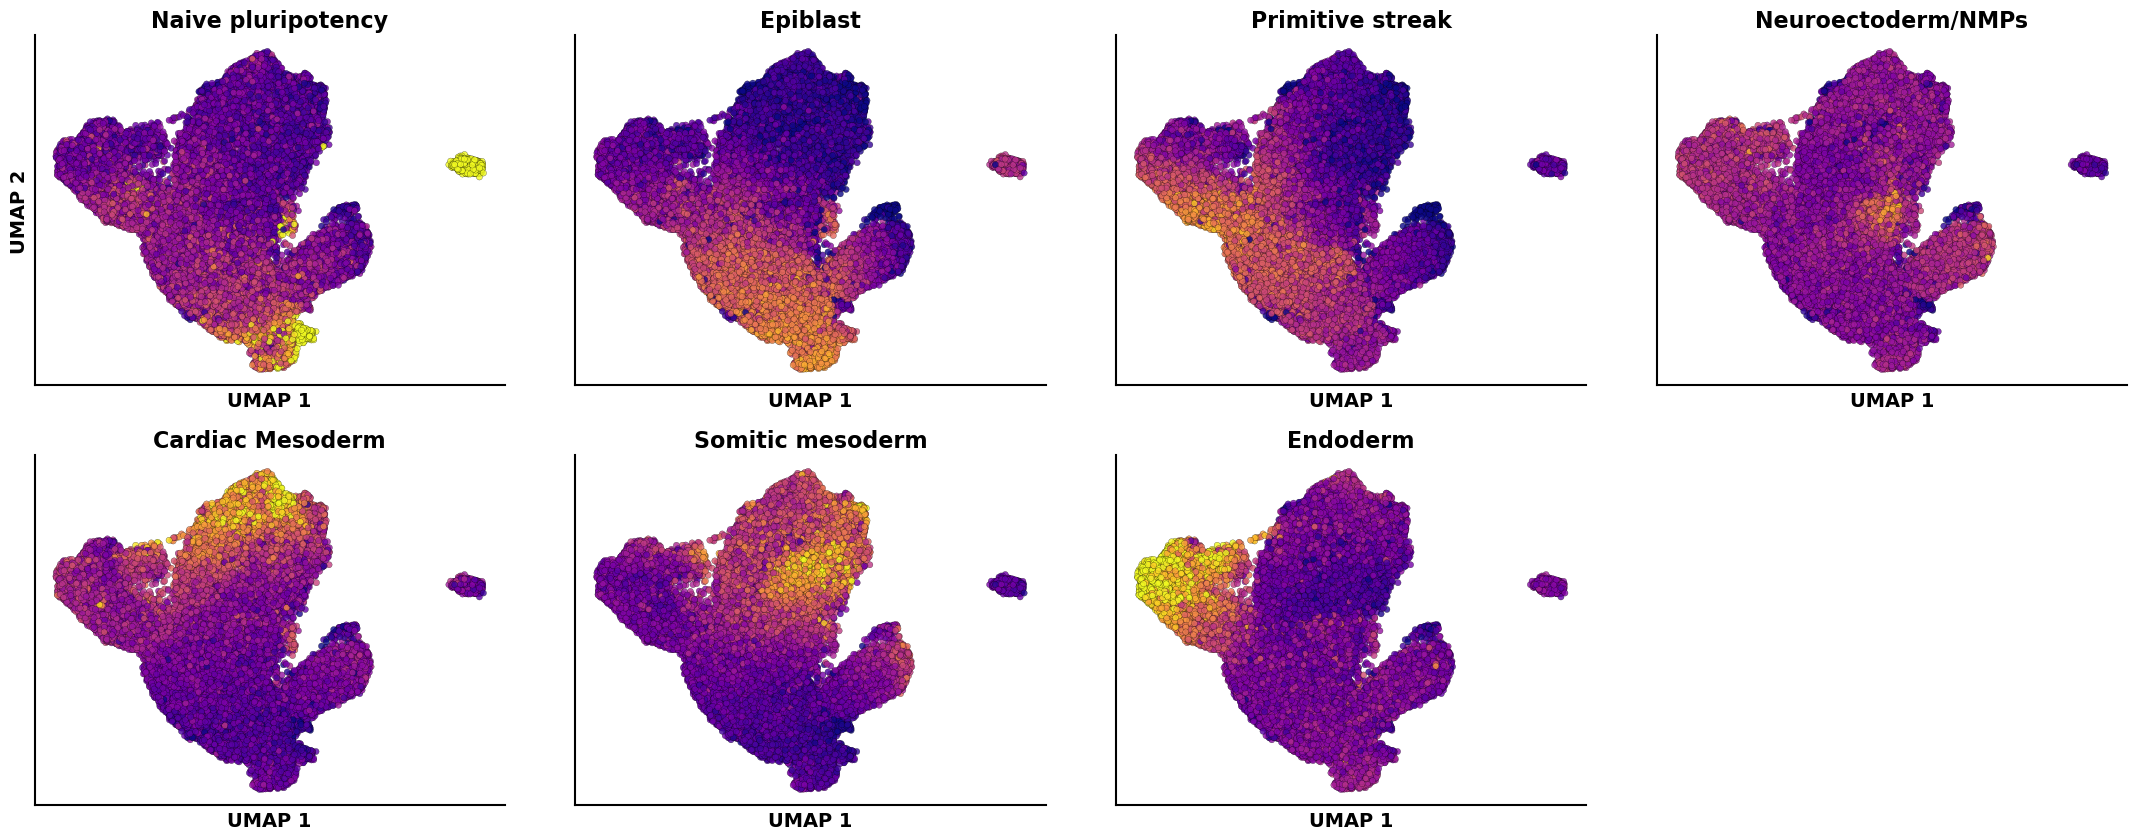

/var/folders/65/gmh15rnx2j18_4kd8skf5y0h0000gq/T/ipykernel_3200/2303205334.py:71: UserWarning: Adding colorbar to a different Figure <Figure size 2700x1000 with 8 Axes> than <Figure size 50x600 with 1 Axes> which fig.colorbar is called on.
  cbar = plt.colorbar(last_sc, cax=ax_cb)


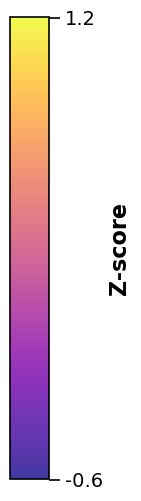

In [ ]:
import matplotlib.pyplot as plt
import numpy as np


n_plots = len(layout)
ncols = 4
nrows = (n_plots + ncols - 1) // ncols  

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(27, nrows*5),  
    sharex=True,
    sharey=True,
)
axes = axes.ravel() 

last_sc = None
for i, cell_type in enumerate(layout):
    ax = axes[i]
    scores = marker_score.get(cell_type, np.full(adata.n_obs, np.nan))

    last_sc = ax.scatter(
        coords[plot_order, 0],
        coords[plot_order, 1],
        c=scores[plot_order],
        cmap="plasma",
        s=20,             
        alpha=0.8,
        edgecolor="k",
        linewidth=0.2,
        vmin=vmin,
        vmax=vmax,
    )

    # Aesthetics
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(cell_type, fontsize=16, fontweight="bold")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("bottom", "left"):
        ax.spines[side].set_linewidth(1.5)

# Leave last plot empty if needed
if n_plots < len(axes):
    for ax in axes[n_plots:]:
        ax.set_visible(False)


plt.subplots_adjust(wspace=0.15, hspace=0.2)

# Shared axis labels
for ax in axes[:n_plots]:
    ax.set_xlabel("UMAP 1", fontsize=14, fontweight="bold")
axes[0].set_ylabel("UMAP 2", fontsize=14, fontweight="bold")

# Save high-quality PNG
fig.savefig("figures/marker_umap.png", dpi=300, bbox_inches="tight")
plt.show()


from matplotlib.ticker import FormatStrFormatter

# ----------------------------
# 4) Plot colorbar separately
# ----------------------------
fig_cb, ax_cb = plt.subplots(figsize=(0.5, 6))  # thinner figure

cbar = plt.colorbar(last_sc, cax=ax_cb)
cbar.set_label("Z-score", fontsize=16, fontweight="bold")

# Ticks + formatting (1 decimal)
cbar.set_ticks([vmin, vmax])
cbar.ax.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))

# Aesthetics
cbar.ax.tick_params(labelsize=14, width=1.2, length=8)
cbar.outline.set_linewidth(1.2)

fig_cb.savefig(
    "figures/marker_umap_colorbar.png",
    dpi=300,
    bbox_inches="tight",
    transparent=True
)

plt.show()


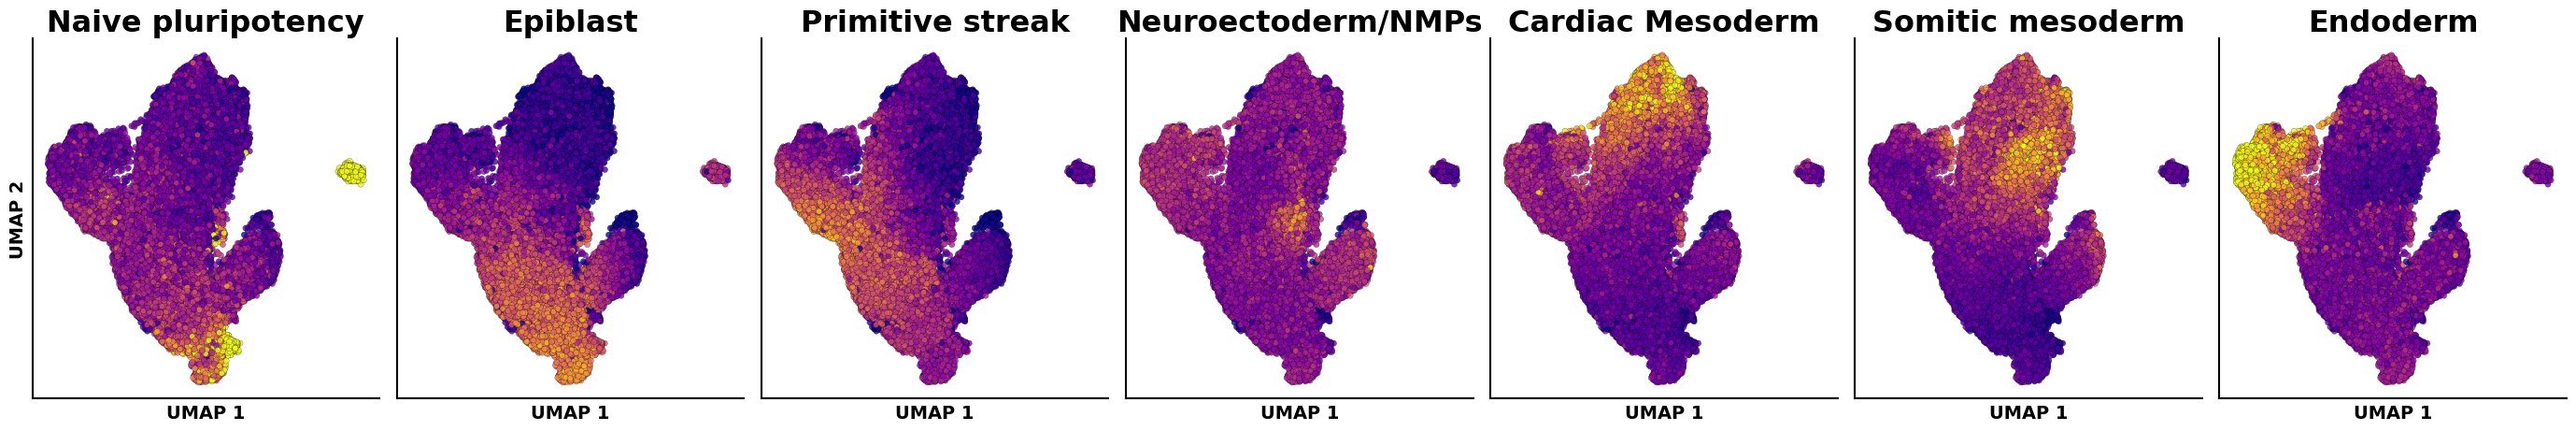

/var/folders/65/gmh15rnx2j18_4kd8skf5y0h0000gq/T/ipykernel_3200/614041622.py:65: UserWarning: Adding colorbar to a different Figure <Figure size 3500x500 with 7 Axes> than <Figure size 50x600 with 1 Axes> which fig.colorbar is called on.
  cbar = plt.colorbar(last_sc, cax=ax_cb)


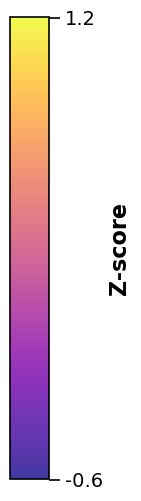

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FormatStrFormatter


n_plots = len(layout)
ncols = n_plots  
nrows = 1

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(ncols*5, 5),  
    sharex=True,
    sharey=True,
)
axes = np.atleast_1d(axes)  

last_sc = None
for i, cell_type in enumerate(layout):
    ax = axes[i]
    scores = marker_score.get(cell_type, np.full(adata.n_obs, np.nan))

    last_sc = ax.scatter(
        coords[plot_order, 0],
        coords[plot_order, 1],
        c=scores[plot_order],
        cmap="plasma",
        s=20,             
        alpha=0.8,
        edgecolor="k",
        linewidth=0.2,
        vmin=vmin,
        vmax=vmax,
    )

    # Aesthetics
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(cell_type, fontsize=23, fontweight="bold")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("bottom", "left"):
        ax.spines[side].set_linewidth(1.5)


plt.subplots_adjust(wspace=0.05, hspace=0.05)

# Shared axis labels
for ax in axes:
    ax.set_xlabel("UMAP 1", fontsize=14, fontweight="bold")
axes[0].set_ylabel("UMAP 2", fontsize=14, fontweight="bold")

# Save high-quality PNG
fig.savefig("figures/marker_umap.png", dpi=300, bbox_inches="tight")
plt.show()


# ----------------------------
# 4) Plot colorbar separately
# ----------------------------
fig_cb, ax_cb = plt.subplots(figsize=(0.5, 6))  # thinner figure for colorbar

cbar = plt.colorbar(last_sc, cax=ax_cb)
cbar.set_label("Z-score", fontsize=16, fontweight="bold")


cbar.set_ticks([vmin, vmax])
cbar.ax.yaxis.set_major_formatter(FormatStrFormatter('%.1f'))

# Aesthetics
cbar.ax.tick_params(labelsize=14, width=1.2, length=8)
cbar.outline.set_linewidth(1.2)

fig_cb.savefig(
    "figures/marker_umap_colorbar.png",
    dpi=300,
    bbox_inches="tight",
    transparent=True
)

plt.show()


/var/folders/65/gmh15rnx2j18_4kd8skf5y0h0000gq/T/ipykernel_3200/874543830.py:62: UserWarning: This figure was using a layout engine that is incompatible with subplots_adjust and/or tight_layout; not calling subplots_adjust.
  plt.subplots_adjust(hspace=0.8, wspace=0.5)


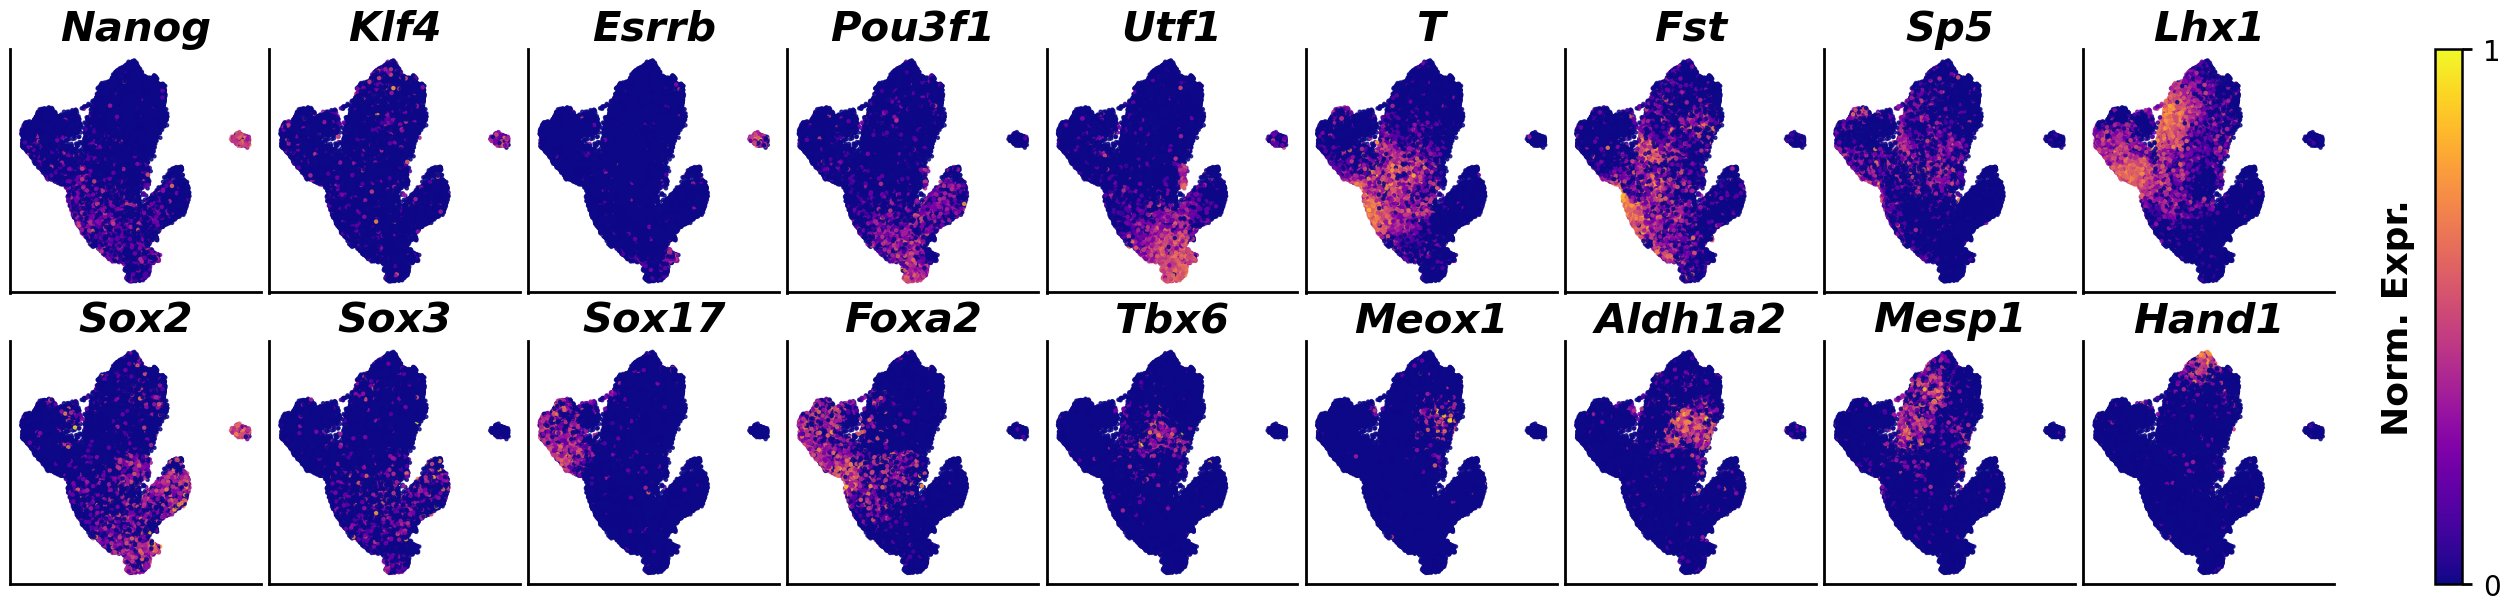

In [ ]:


# List of genes to plot
genes_to_plot = [
    'Nanog', 'Klf4', 'Esrrb', 'Pou3f1', 'Utf1', 'T', 'Fst', 'Sp5', 'Lhx1',
    'Sox2', 'Sox3', 'Sox17', 'Foxa2', 'Tbx6', 'Meox1', 'Aldh1a2', 'Mesp1', 'Hand1'
]

# Layout
n_cols = 9
n_rows = 2

# Create figure
fig, axes = plt.subplots(n_rows, n_cols, figsize=(25, 6), constrained_layout=True)

# Use consistent colormap and fixed normalization (0–1 for all)
norm = Normalize(vmin=0, vmax=1)

# Loop over genes to plot
coords = adata.obsm['X_umap']
for idx, (gene, ax) in enumerate(zip(genes_to_plot, axes.flatten())):
    # Get expression (dense 1D array)
    if gene in adata.var_names:
        expr = adata[:, gene].X.toarray().flatten()
    else:
        expr = np.zeros(coords.shape[0])  # fallback if missing gene
    
    # Normalise each gene's expression between 0–1
    if np.nanmax(expr) > np.nanmin(expr):  # avoid divide-by-zero
        expr = (expr - np.nanmin(expr)) / (np.nanmax(expr) - np.nanmin(expr))
    else:
        expr = np.zeros_like(expr)
    
    # Scatter plot
    ax.scatter(
        coords[:, 0], coords[:, 1],
        c=expr, cmap='plasma', norm=norm,
        s=5, alpha=0.8
    )

    # Format axes and titles
    ax.set_title(gene, fontsize=30, fontweight='bold', fontstyle='italic')  
    for spine in ['left', 'bottom']:
        ax.spines[spine].set_linewidth(2)
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)
    ax.set_xticks([])
    ax.set_yticks([])

# Shared colorbar (0–1 normalized)
sm = plt.cm.ScalarMappable(norm=norm, cmap='plasma')
sm.set_array([])
cbar = fig.colorbar(sm, ax=axes.ravel().tolist(), fraction=0.02, pad=0.02)

# Customize colorbar appearance
cbar.ax.yaxis.set_label_position("left")
cbar.set_ticks([0, 1])  # Only show 0 and 1
cbar.ax.set_yticklabels(['0', '1'], fontsize=50)
cbar.set_label("Norm. Expr.", fontsize=26, fontweight='bold', labelpad=15)
cbar.ax.tick_params(labelsize=20, width=2, length=7, pad=8)
cbar.outline.set_linewidth(1.8)

# Layout adjustment
plt.subplots_adjust(hspace=0.8, wspace=0.5)
plt.show()


In [41]:
# Perform clustering - using highly variable genes
sc.tl.louvain(adata, resolution=2.5, key_added='louvain_r2.5', random_state=0)

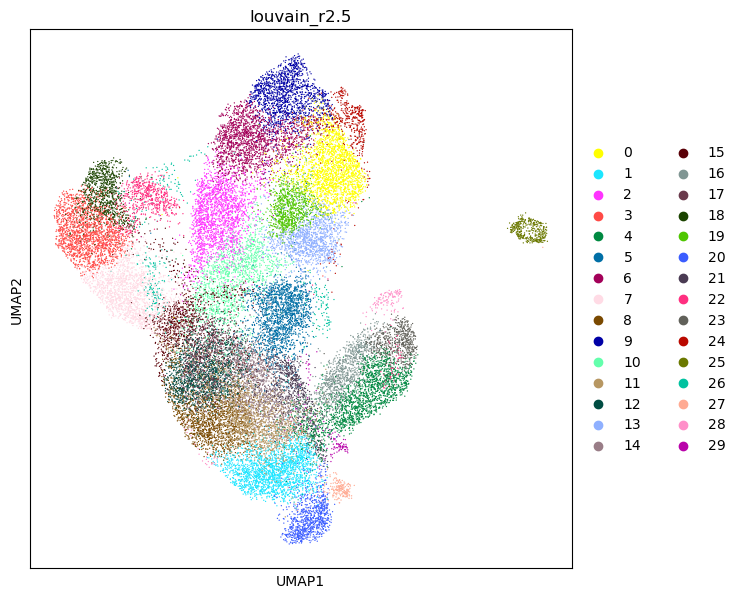

In [42]:
sc.pl.umap(adata, color = 'louvain_r2.5')

In [43]:
cell_type_dict = {
    '0': 'Somitic mesoderm',
    '1': 'Epiblast',
    '2': 'Early cardiac mesoderm',
    '3': 'Endoderm',
    '4': 'Wnt. inh. state',
    '5': 'Neuroectoderm/NMPs',
    '6': 'Early cardiac mesoderm',
    '7': 'Early endoderm',
    '8': 'Primitive streak',
    '9': 'Cardiac mesoderm',
    '10': 'Early somitic mesoderm',
    '11':'Primitive streak',
    '12': 'Primitive streak',
    '13': 'Early somitic mesoderm',
    '14':  'Primitive streak',
    '15': 'Primitive streak',
    '16': 'Wnt. inh. state',
    '17':  'Primitive streak',
    '18': 'Endoderm',
    '19': 'Early somitic mesoderm',
    '20': 'Epiblast',
    '21': 'Early neuroectoderm/NMPs',
    '22': 'Endoderm',
    '23': 'Wnt. inh. state',
    '24': 'Cardiac mesoderm',
    '25': 'Naive pluripotency',
    '26': 'Endoderm',
    '27': 'Ectopic pluripotency',
    '28': 'Wnt. inh. state',
    '29': 'Wnt. inh. state'
}

colormap_ct = {
     'Naive pluripotency': 'saddlebrown' ,
     'Ectopic pluripotency': 'darkgoldenrod',
     'Epiblast': 'goldenrod' ,
     'Primitive streak': 'gold',
     'Wnt. inh. state': 'deeppink',
     'Early neuroectoderm/NMPs': 'darkorange' ,
     'Neuroectoderm/NMPs': 'red',
     'Early endoderm': 'lightgreen',
     'Endoderm': 'forestgreen',
     'Early cardiac mesoderm': 'lightskyblue',
     'Cardiac mesoderm': 'steelblue',
     'Early somitic mesoderm':  'plum' ,
     'Somitic mesoderm' : 'mediumpurple', 

}

In [44]:
adata.obs['Cell type'] = (
    adata.obs['louvain_r2.5']
    .astype(str)
    .map(cell_type_dict)
)
adata.obs['Color'] = adata.obs['Cell type'].map(colormap_ct)


In [45]:
adata.obs['Cell type'].unique()

array(['Naive pluripotency', 'Endoderm', 'Ectopic pluripotency',
       'Wnt. inh. state', 'Epiblast', 'Early neuroectoderm/NMPs',
       'Primitive streak', 'Early cardiac mesoderm', 'Cardiac mesoderm',
       'Neuroectoderm/NMPs', 'Somitic mesoderm', 'Early somitic mesoderm',
       'Early endoderm'], dtype=object)

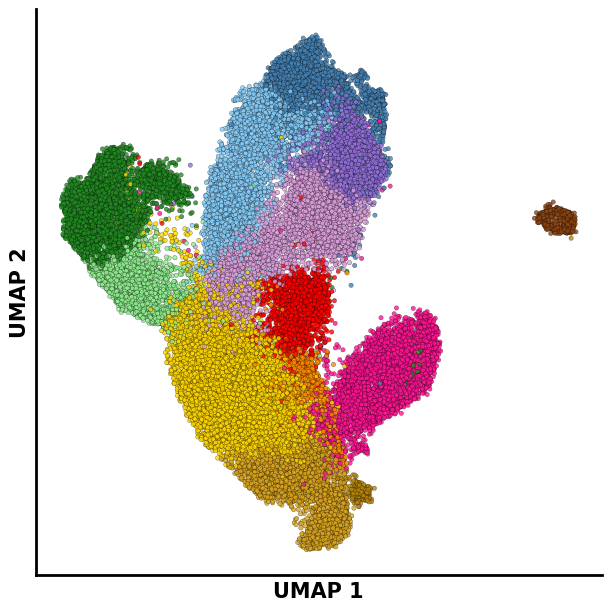

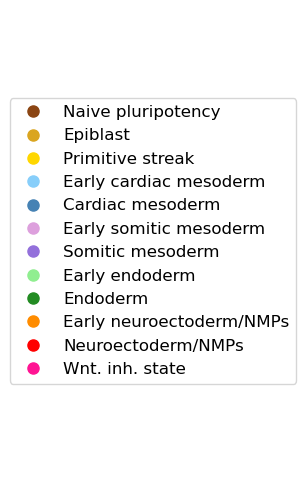

In [ ]:
adata = adata[adata.obs['louvain_r2.5'] != '26'].copy()
adata = adata[adata.obs['louvain_r2.5'] != '28'].copy()

# --- 0) Define desired legend order  ---
legend_order = [
    'Naive pluripotency', 'Exiting pluripotency', 'Epiblast', 'Primitive streak',
    'Early cardiac mesoderm', 'Cardiac mesoderm',
    'Early somitic mesoderm', 'Somitic mesoderm',
    'Early endoderm', 'Endoderm',
    'Early neuroectoderm/NMPs', 'Neuroectoderm/NMPs', 'Wnt. inh. state'
]

# --- 1) Build color map from adata  ---
unique_cell_types = adata.obs['Cell type'].unique()
cmap = {ctype: adata[adata.obs['Cell type'] == ctype].obs['Color'].iloc[0] for ctype in unique_cell_types}


legend_types_present = [ct for ct in legend_order if ct in cmap]

# --- 2) Randomise draw order so clusters don't overplot ---
N = adata.n_obs if hasattr(adata, "n_obs") else len(adata.obs)
perm = np.random.permutation(N)

X = adata.obsm['X_umap'][perm, 0]
Y = adata.obsm['X_umap'][perm, 1]
colors = adata.obs['Color'].iloc[perm].values

# --- 3) Main UMAP figure ---
fig, ax = plt.subplots(figsize=(6, 6), constrained_layout=True)

ax.scatter(
    X, Y,
    c=colors,
    s=10,
    alpha=0.8,
    edgecolor="black",
    linewidth=0.2
)

ax.set_xlabel("UMAP 1", fontsize=15, fontweight="bold")
ax.set_ylabel("UMAP 2", fontsize=15, fontweight="bold")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_linewidth(2)
ax.spines["left"].set_linewidth(2)
ax.set_xticks([])
ax.set_yticks([])
ax.tick_params(labelsize=10)

fig.savefig(
    "figures/umap_celltype.png",
    dpi=500,
    bbox_inches="tight",
    transparent=True
)

plt.show()

# --- 4) Separate legend figure  ---
fig_legend = plt.figure(figsize=(3, 6))
ax_legend = fig_legend.add_subplot(111)
ax_legend.axis("off")

legend_handles = [
    mlines.Line2D([], [], marker='o', markersize=8, linestyle='None',
                  color=cmap[ctype], label=ctype)
    for ctype in legend_types_present
]

ax_legend.legend(
    handles=legend_handles,
    title="",
    fontsize=12,
    loc="center",
    frameon=True
)

fig_legend.savefig(
    "figures/umap_celltype_legend.png",
    dpi=500,
    bbox_inches="tight",
    transparent=True
)
plt.show()


In [48]:
genes_in_adata = set(adata.var.index)

filtered_cell_type_markers_dict = {
    cell_type: [g for g in genes if g in genes_in_adata]
    for cell_type, genes in cell_type_markers_dict.items()
}


## Cell type proportions

In [49]:
df = adata.obs
colormap_ct = df[['Cell type', 'Color']].set_index('Cell type').drop_duplicates().to_dict()['Color']

/var/folders/65/gmh15rnx2j18_4kd8skf5y0h0000gq/T/ipykernel_3200/4250782022.py:22: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  proportions = d.groupby(['Time', 'Cell type']).size().unstack(fill_value=0)
/var/folders/65/gmh15rnx2j18_4kd8skf5y0h0000gq/T/ipykernel_3200/4250782022.py:22: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  proportions = d.groupby(['Time', 'Cell type']).size().unstack(fill_value=0)
/var/folders/65/gmh15rnx2j18_4kd8skf5y0h0000gq/T/ipykernel_3200/4250782022.py:22: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass obs

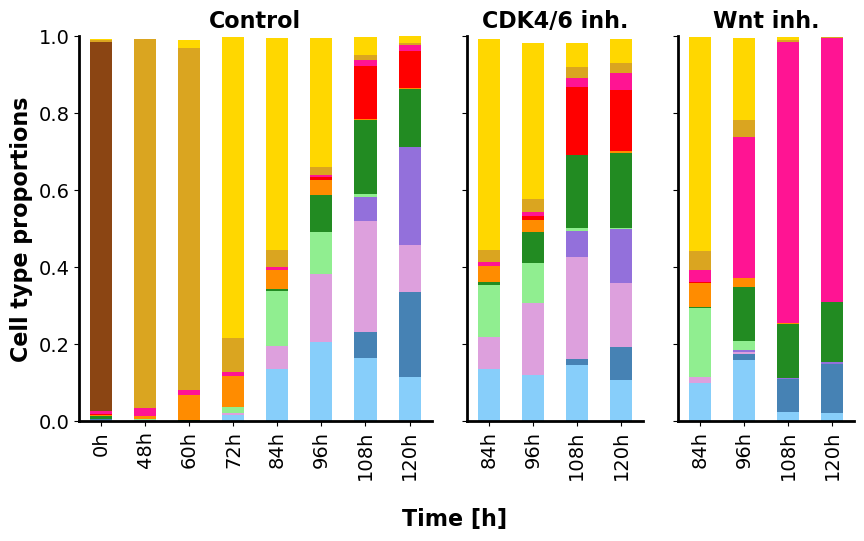

In [ ]:
# Desired order of cell types
legend_order = [
    
    'Early cardiac mesoderm', 'Cardiac mesoderm',
    'Early somitic mesoderm', 'Somitic mesoderm',
    'Early endoderm', 'Endoderm',
    'Early neuroectoderm/NMPs', 'Neuroectoderm/NMPs', 'Wnt. inh. state',
    'Naive pluripotency', 'Exiting pluripotency', 'Epiblast', 'Primitive streak',
]
fig, ax = plt.subplots(
    1, 3,
    gridspec_kw={'width_ratios': [2, 1, 1], 'wspace': 0.15},
    figsize=(10, 5)
)

ax = ax.flatten()

for j, cond in enumerate(df.Condition.unique()):
    d = df[df.Condition == cond]

    # Calculate proportions
    proportions = d.groupby(['Time', 'Cell type']).size().unstack(fill_value=0)
    proportions = proportions.div(proportions.sum(axis=1), axis=0)
    proportions.dropna(inplace=True)

  
    cols_present = [c for c in legend_order if c in proportions.columns]
    proportions = proportions[cols_present]
    # ----------------------------------------------------------------------

    proportions.plot(
        kind='bar',
        stacked=True,
        color=[colormap_ct.get(col, 'black') for col in cols_present],
        ax=ax[j],
        legend=False
    )

    ax[j].tick_params(labelsize=14)

# Titles
ax[0].set_title('Control', fontsize=16, fontweight="bold")
ax[1].set_title('CDK4/6 inh.', fontsize=16, fontweight="bold")
ax[2].set_title('Wnt inh.', fontsize=16, fontweight="bold")

# Remove x labels
for a in ax:
    a.set_xlabel('')

# Y-axis labels
ax[0].set_ylabel('Cell type proportions', fontsize=16, fontweight="bold")
ax[1].set_yticklabels([])
ax[2].set_yticklabels([])

# X-axis label
fig.text(0.5, -0.1, 'Time [h]', ha='center', fontsize=16, fontweight="bold")

# Spine thickness
for i in range(3):
    ax[i].set_ylim([0, 1])
    for spine in ['left', 'bottom']:
        ax[i].spines[spine].set_linewidth(2)
    for spine in ['right', 'top']:
        ax[i].spines[spine].set_linewidth(0)
        

fig.savefig(
    "figures/celltype_proportions.png",
    dpi=500,
    bbox_inches="tight",
    transparent=True
)

plt.show()


/var/folders/65/gmh15rnx2j18_4kd8skf5y0h0000gq/T/ipykernel_3200/3121824121.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(['Condition', 'Cell type'])


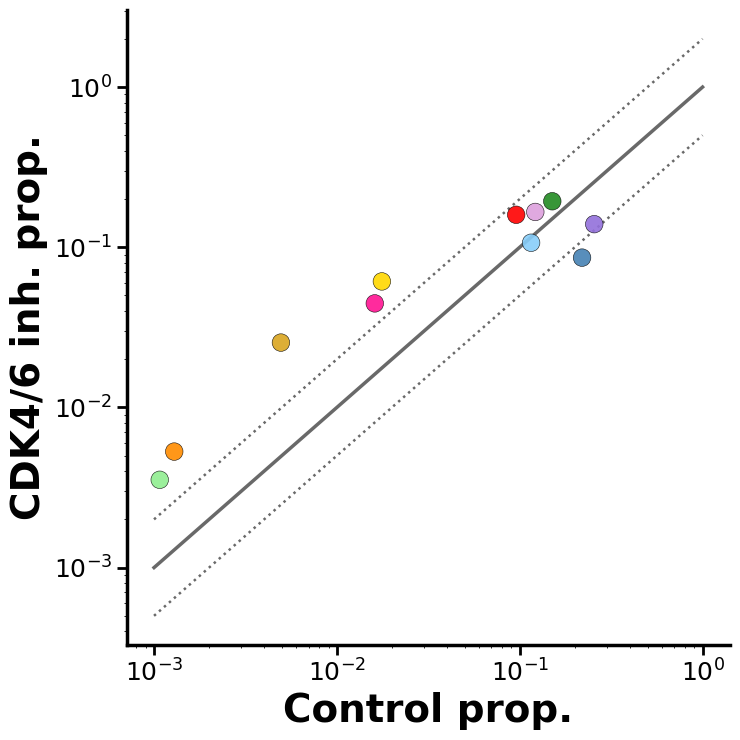

In [54]:


# --- Filter for the 120h time point ---
proportions_120h = (
    df[df['Time'] == '120h']
    .groupby(['Condition', 'Cell type'])
    .size()
    .unstack(fill_value=0)
)

proportions_120h = proportions_120h.div(
    proportions_120h.sum(axis=1), axis=0
)

# Reorder columns according to legend order, keep only present
cols_present = [c for c in legend_order if c in proportions_120h.columns]
proportions_120h = proportions_120h[cols_present]

# Extract Control and CDK4/6 inh
control = proportions_120h.loc['ctrl']
cdk4 = proportions_120h.loc['cdk']

# Colors
colors = [colormap_ct.get(ct, 'black') for ct in cols_present]

# --- Plot ---
fig, ax = plt.subplots(figsize=(7.5, 7.5))

# Scatter points
ax.scatter(
    control.values, cdk4.values,
    c=colors,
    s=160,
    alpha=0.9,
    edgecolor='k',
    linewidth=0.4
)

# --- Reference lines ---
x_ref = np.logspace(-3, 0, 300)

# y = x (solid)
ax.plot(
    x_ref, x_ref,
    color='dimgray',
    linewidth=2.5,
    linestyle='-',
    zorder=0
)

# ±2-fold (dotted)
ax.plot(
    x_ref, 2 * x_ref,
    color='dimgray',
    linewidth=1.8,
    linestyle=':',
    zorder=0
)

ax.plot(
    x_ref, x_ref / 2,
    color='dimgray',
    linewidth=1.8,
    linestyle=':',
    zorder=0
)

# --- Log scale ---
ax.set_xscale('log')
ax.set_yscale('log')

# Tick locations and formatting
loc = LogLocator(base=10.0)
fmt = LogFormatterMathtext(base=10.0)
ax.xaxis.set_major_locator(loc)
ax.xaxis.set_major_formatter(fmt)
ax.yaxis.set_major_locator(loc)
ax.yaxis.set_major_formatter(fmt)

# Axis limits


# Labels
ax.set_xlabel("Control prop.", fontsize=28, fontweight='bold')
ax.set_ylabel("CDK4/6 inh. prop.", fontsize=28, fontweight='bold')

# Spine styling
for side in ('top', 'right'):
    ax.spines[side].set_visible(False)

ax.spines['left'].set_linewidth(2.5)
ax.spines['bottom'].set_linewidth(2.5)

ax.tick_params(
    axis='both',
    which='major',
    width=2.0,
    length=7,
    labelsize=18
)

# No grid
ax.grid(False)

plt.tight_layout()


fig.savefig(
    "figures/celltype_proportions_scatter.png",
    dpi=500,
    bbox_inches="tight",
    transparent=True
)

plt.show()


In [29]:
adata.write("INPUT/scRNAseq/scRNAseq_annotated.h5ad")


In [30]:
adata.obs.to_csv("INPUT/scRNAseq/celltype_annotation.csv")